# Retail inventory on M5 (Walmart) sales

The demand model is fitted on the first 546 days of one product's sales (FOODS_3_377 at store WI_1). Every method is
tuned and trained on samples from that model only: 10% of the 3M-step budget with 10 seeds for tuning (smallest mean
exact gap), then 20 test seeds on the full budget. The learned policies are then replayed on the real sales of the
last 184 days.

In [1]:
import csv
import tempfile
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from ie692_rl.core.exact import ExactScorer
from ie692_rl.core.spmd import run_spmd
from ie692_rl.core.tomc import TOMC
from ie692_rl.enhancements.bregman_spmd import KL, Euclidean, Tsallis
from ie692_rl.enhancements.true_online_td import TrueOnlineTD
from ie692_rl.envs.inventory import SERIES_FILE, RetailInventory, load_series
from ie692_rl.plotting import (
    INK,
    INK_SECONDARY,
    SERIES,
    STYLE,
    _decimal_axis,
    _style_axes,
    plot_learning_curves,
)

TRAIN, BUDGET, TUNING_BUDGET = 546, 3_000_000, 300_000
TUNING_SEEDS, TEST_SEEDS = range(100, 110), range(200, 220)
STEPS = (0.1, 1.0, 10.0)
GRIDS = {  # method -> settings (the config.cfg grids for Inventory)
    "baseline": [{"eta": e} for e in STEPS],
    "entropy_reg": [{"eta": e, "tau": t} for e, t in product(STEPS, (0.001, 0.01, 0.1))],
    "true_online_td": [
        {"eta": e, "td_eta": a, "lam": lam}
        for e, a, lam in product(STEPS, (0.02, 0.1, 0.5), (0.5, 0.8, 0.95))
    ],
    "bregman_euclidean": [{"eta": e} for e in STEPS],
    "bregman_tsallis": [{"eta": e, "index": i} for e, i in product(STEPS, (0.2314, 0.5, 3.5))],
}

units, weekdays, _ = load_series()
with open(SERIES_FILE) as handle:
    prices = np.array([float(r["sell_price"]) for r in csv.DictReader(handle)])
env = RetailInventory(units[:TRAIN], weekdays[:TRAIN], prices[:TRAIN].mean())
scorer = ExactScorer(env)


def run(method, s, seed, budget):
    """One SPMD run of a method with settings s."""
    if method == "true_online_td":
        estimator = TrueOnlineTD(eta=s["td_eta"], lam=s["lam"], n_steps=20_000)
    else:
        estimator = TOMC(0.01)
    divergences = {"bregman_euclidean": Euclidean, "bregman_tsallis": lambda: Tsallis(s["index"])}
    divergence = divergences.get(method, KL)()
    return run_spmd(env, estimator, divergence, s["eta"], budget, seed, tau=s.get("tau", 0.0), scorer=scorer)


def tune(method):
    """Settings with the smallest mean gap, among those where every seed made an update."""
    scores = []
    for s in GRIDS[method]:
        results = [run(method, s, seed, TUNING_BUDGET) for seed in TUNING_SEEDS]
        if all(any(r.status == "updated" for r in result.history) for result in results):
            scores.append((np.mean([result.history[-1].gap for result in results]), s))
    return min(scores, key=lambda x: x[0])[1]


chosen = {method: tune(method) for method in GRIDS}
runs = {m: [run(m, chosen[m], seed, BUDGET) for seed in TEST_SEEDS] for m in GRIDS}

## Learning curves

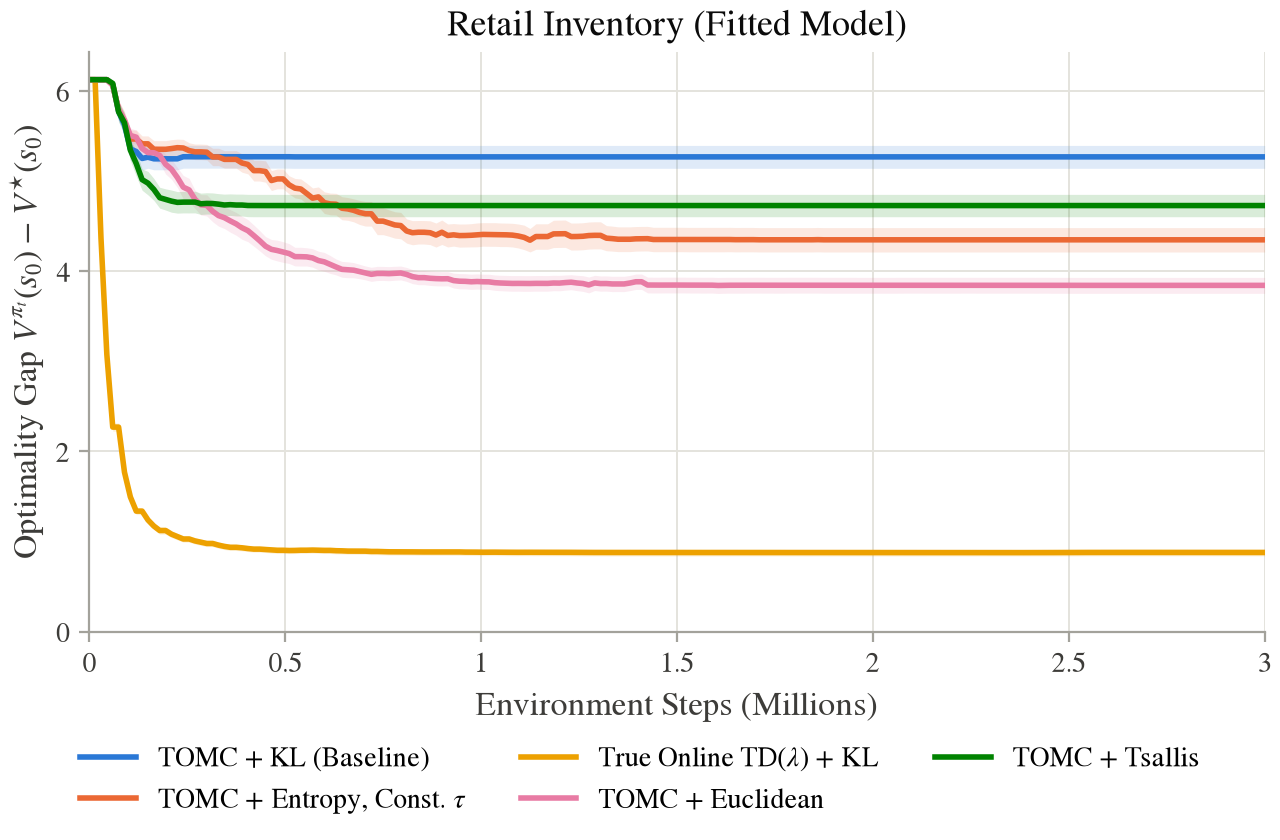

In [2]:
# unused third slot: every method keeps its usual color
slots = ["baseline", "entropy_reg", "unused", "true_online_td", "bregman_euclidean", "bregman_tsallis"]
labels = {
    "baseline": "TOMC + KL (Baseline)",
    "entropy_reg": r"TOMC + Entropy, Const. $\tau$",
    "true_online_td": r"True Online TD($\lambda$) + KL",
    "bregman_euclidean": "TOMC + Euclidean",
    "bregman_tsallis": "TOMC + Tsallis",
}
history = [
    {"problem": "Inventory", "method": m, "seed": seed, **record.as_dict()}
    for m in GRIDS
    for seed, result in zip(TEST_SEEDS, runs[m], strict=True)
    for record in result.history
]
with tempfile.TemporaryDirectory() as folder:
    title = {"Inventory": "Retail Inventory (Fitted Model)"}
    (path,) = plot_learning_curves(history, {"Inventory": BUDGET}, slots, labels, title, Path(folder))
    display(Image(filename=str(path), width=640))

## Profit on held-out sales

In [3]:
def replay(policy, demand_pmfs, days):
    """Expected profit of each day, starting from an empty shelf, when demand on day t follows demand_pmfs[t]."""
    stock = np.zeros(env.n_stock)
    stock[0] = 1.0
    profit = np.zeros(len(days))
    for t, (pmf, w) in enumerate(zip(demand_pmfs, days, strict=True)):
        following, demands = np.zeros(env.n_stock), np.flatnonzero(pmf)
        for k in np.flatnonzero(stock > 0):
            s = int(env.encode(int(k), int(w)))
            probs = policy[s] if s >= 0 else np.eye(env.n_actions)[0]  # unseen state: order nothing
            for a in np.flatnonzero(probs):
                cost, left, _ = env._outcome(np.array(k), np.array(w), np.array(a), demands)
                weight = stock[k] * probs[a] * pmf[demands]
                profit[t] -= weight @ cost
                np.add.at(following, left, weight)
        stock = following
    return profit


# reference policies
m = scorer.model
q = m.costs + scorer.gamma * np.einsum("san,san->sa", m.probs, scorer.optimal_values[m.next_states])
means = [units[:TRAIN][weekdays[:TRAIN] == d].mean() for d in range(7)]
weekday_mean = np.zeros_like(q)
for s in range(env.n_states):
    stock, day = env.decode(s)
    weekday_mean[s, max(0, round(means[int(day)]) - int(stock))] = 1
policies = {method: [result.policy for result in runs[method]] for method in GRIDS}
policies["optimum"] = [np.eye(env.n_actions)[q.argmin(1)]]
policies["weekday_mean"] = [weekday_mean]
policies["uniform"] = [np.full_like(q, 1 / env.n_actions)]

days = weekdays[TRAIN:]
real = [np.eye(int(units.max()) + 1)[d] for d in units[TRAIN:]]
model = [env.demand_pmf[w] for w in days]
n_days, rng = len(days), np.random.default_rng(0)
starts = rng.integers(0, n_days, (10_000, n_days // 7 + 1))  # circular 7-day block bootstrap
sample = ((starts[:, :, None] + np.arange(7)) % n_days).reshape(len(starts), -1)[:, :n_days]

profit = {}
for name, group in policies.items():
    daily = np.mean([replay(p, real, days) for p in group], axis=0)
    low, high = np.percentile(daily[sample].mean(1), [2.5, 97.5])
    predicted = np.mean([replay(p, model, days).mean() for p in group])
    profit[name] = {"real": daily.mean(), "low": low, "high": high, "model": predicted}

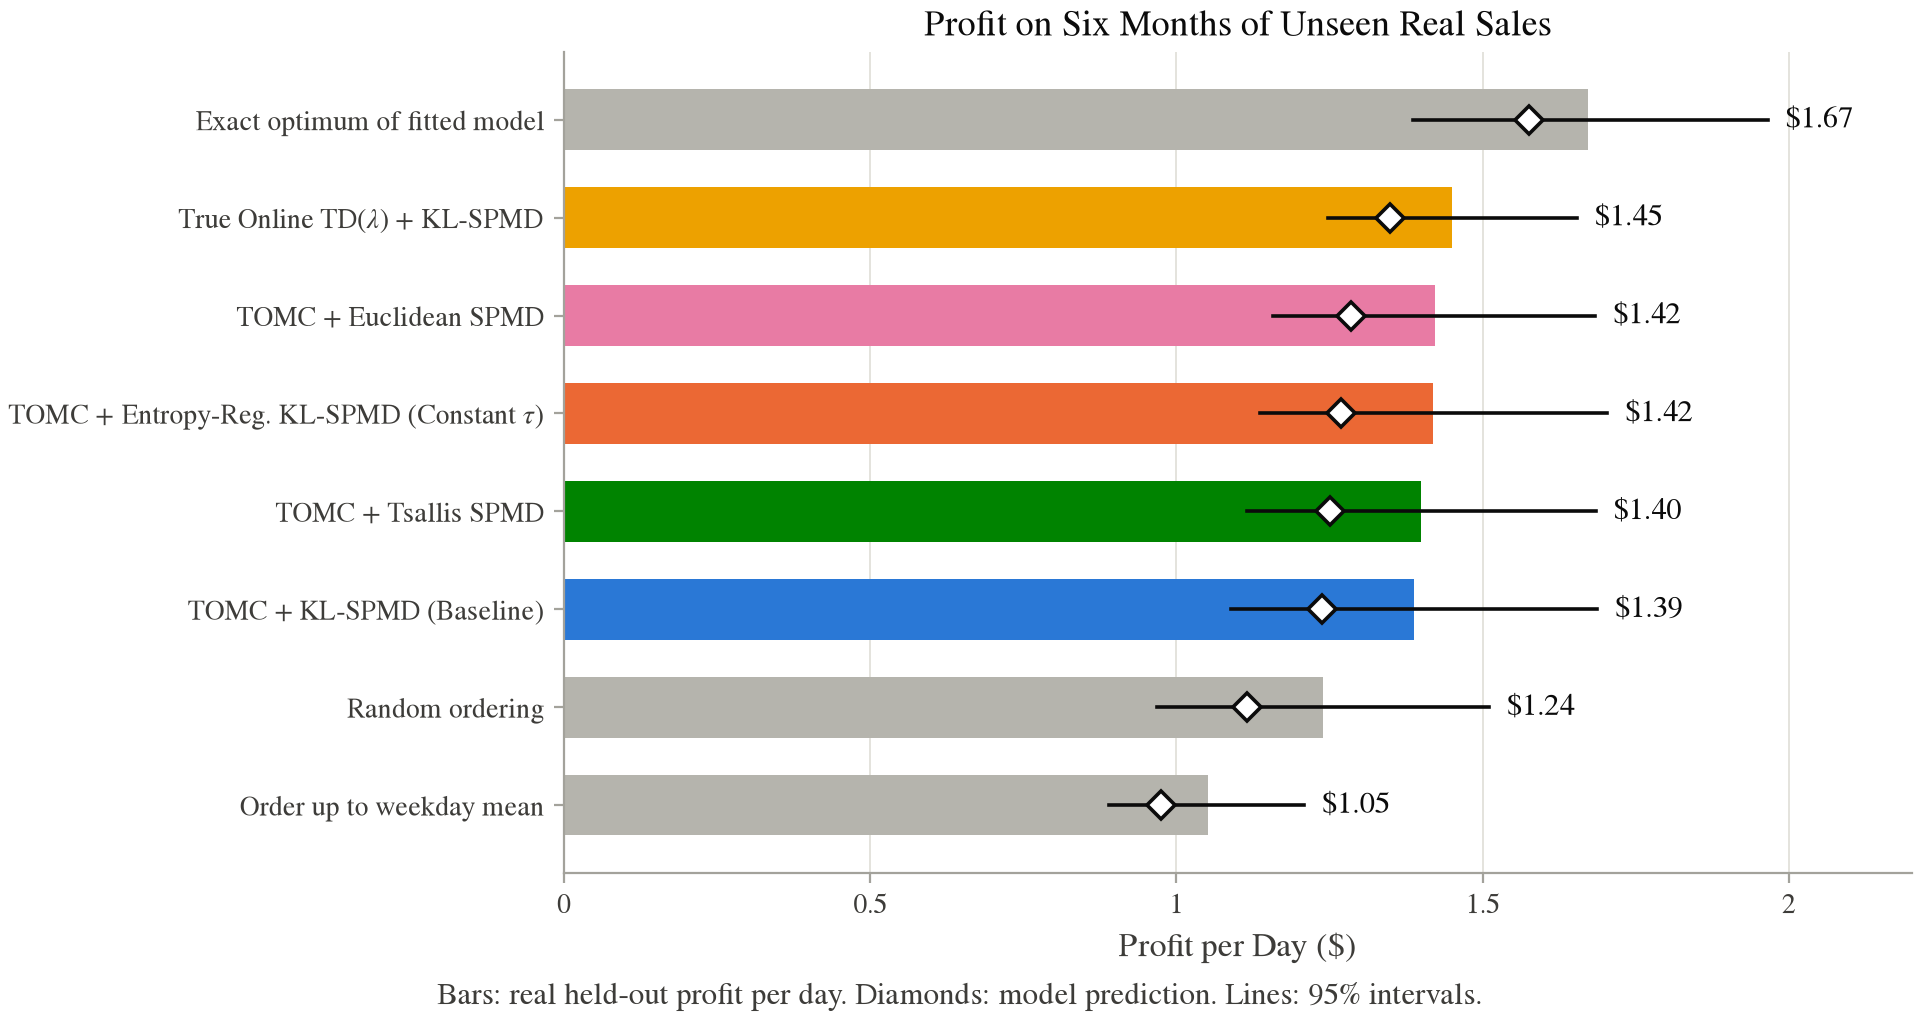

In [4]:
names = {
    "uniform": "Random ordering",
    "weekday_mean": "Order up to weekday mean",
    "baseline": "TOMC + KL-SPMD (Baseline)",
    "entropy_reg": r"TOMC + Entropy-Reg. KL-SPMD (Constant $\tau$)",
    "bregman_euclidean": "TOMC + Euclidean SPMD",
    "bregman_tsallis": "TOMC + Tsallis SPMD",
    "true_online_td": r"True Online TD($\lambda$) + KL-SPMD",
    "optimum": "Exact optimum of fitted model",
}
order = ["weekday_mean", "uniform", *sorted(GRIDS, key=lambda k: profit[k]["real"]), "optimum"]
colors = dict(zip(slots, SERIES, strict=False))

with plt.rc_context(STYLE), tempfile.TemporaryDirectory() as folder:
    fig, ax = plt.subplots(figsize=(9.6, 5.1), layout="constrained")
    for y, k in enumerate(order):
        r = profit[k]
        ax.barh(y, r["real"], 0.62, color=colors.get(k, "#b5b4ad"), zorder=2)
        ax.plot([r["low"], r["high"]], [y, y], color=INK, lw=1.3, zorder=3)
        ax.plot(r["model"], y, marker="D", ms=7, mfc="white", mec=INK, mew=1.3, ls="", zorder=4)
        ax.text(r["high"] + 0.03, y, f"${r['real']:.2f}", va="center", color=INK, fontsize=11)
    ax.set_yticks(range(len(order)), [names[k] for k in order])
    ax.set_xlim(0, 2.2)
    _decimal_axis(ax.xaxis)
    _style_axes(ax, "Profit on Six Months of Unseen Real Sales", "Profit per Day ($)", "")
    ax.grid(axis="y", visible=False)
    fig.supxlabel(
        "Bars: real held-out profit per day. Diamonds: model prediction. Lines: 95% intervals.",
        fontsize=11,
        color=INK_SECONDARY,
    )
    path = Path(folder) / "heldout_profit.png"
    fig.savefig(path)
    plt.close(fig)
    display(Image(filename=str(path), width=960))